# Assignment 57 — Week 7, Day 2
## Topic: Deep Learning — Multilayer Perceptron (MLP)

**Objective:** Complete the exercise on a multilayer perceptron (MLP).

**Reference:** https://machinelearningmastery.com/neural-networks-crash-course/

A **multilayer perceptron (MLP)** is the classic neural network: layers of neurons where every neuron in one layer is connected to every neuron in the next. Following the Machine Learning Mastery crash course, the key ideas are:

- **Neurons** – compute a weighted sum of their inputs plus a bias, then apply an **activation function**.
- **Networks of neurons** – an **input layer** (the data), one or more **hidden layers** and an **output layer**.
- **Training** – data is fed through the network, the error is measured, and **stochastic gradient descent** with **backpropagation** updates the weights, one small batch at a time, for many **epochs**.

The notebook implements an MLP with Keras on the Pima Indians Diabetes data set (`diabetes.csv`, which must be in the same folder).

**Diagram:** Every neuron does the same three things: weight its inputs, add a bias, apply an activation.

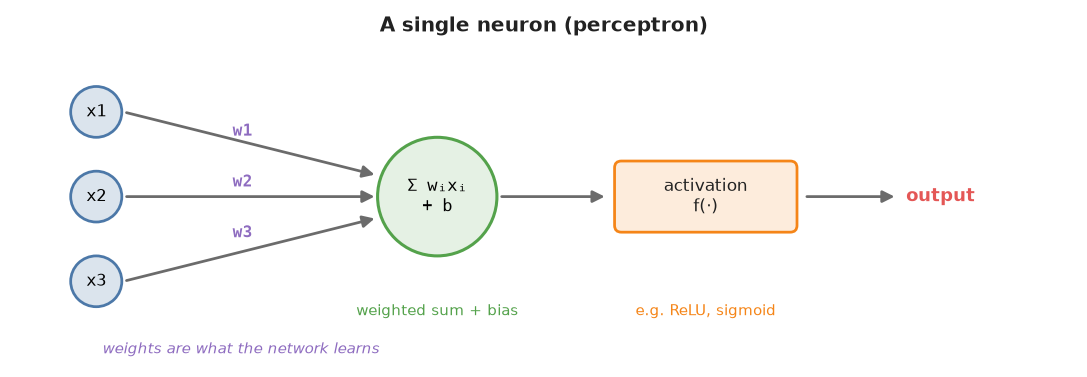

**Set up TensorFlow and Keras**

In [1]:
import os
import logging

# Hide TensorFlow's start-up log messages so the outputs stay readable
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
logging.getLogger("tensorflow").setLevel(logging.ERROR)

import numpy as np
import tensorflow as tf
from tensorflow import keras

tf.get_logger().setLevel(logging.ERROR)
keras.utils.set_random_seed(42)  # makes the results repeatable
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


**Explanation:** Keras is the high-level neural network API that ships with TensorFlow. The environment settings hide TensorFlow's start-up log messages, and set_random_seed() makes the results repeatable.

**Activation functions**

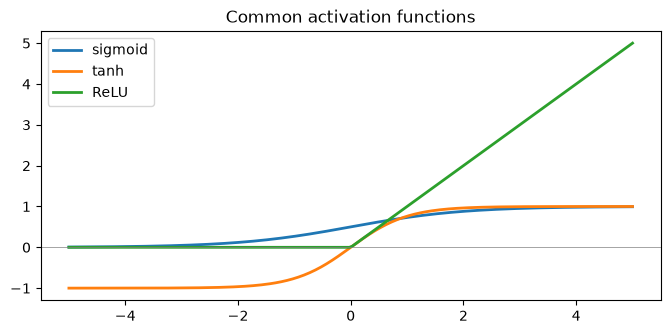

In [2]:
import numpy as np
import matplotlib.pyplot as plt

z = np.linspace(-5, 5, 200)
activations = {
    "sigmoid": 1 / (1 + np.exp(-z)),
    "tanh": np.tanh(z),
    "ReLU": np.maximum(0, z),
}

plt.figure(figsize=(8, 3.5))
for name, values in activations.items():
    plt.plot(z, values, label=name, linewidth=2)
plt.axhline(0, color="grey", linewidth=0.5)
plt.legend()
plt.title("Common activation functions")
plt.show()

**Explanation:** The activation function decides a neuron's output. Sigmoid outputs 0 to 1 (useful for probabilities), tanh outputs -1 to 1, and ReLU outputs 0 for negative inputs and the input itself otherwise. ReLU is the usual choice for hidden layers because it trains quickly.

**Prepare the data**

In [3]:
import pandas as pd

dataset = pd.read_csv("diabetes.csv").values

X = dataset[:, 0:8].astype("float32")
y = dataset[:, 8].astype("float32")

print("Input shape:", X.shape)
print("Output shape:", y.shape)
print("Share of patients with diabetes:", round(y.mean(), 3))

Input shape: (768, 8)
Output shape: (768,)
Share of patients with diabetes: 0.349


**Explanation:** The 8 medical measurements are the inputs and the 9th column (label) is the output. Neural networks work with numbers, so everything is converted to floats.

**Diagram:** The layers of the network, from the 8 input features to one output probability.

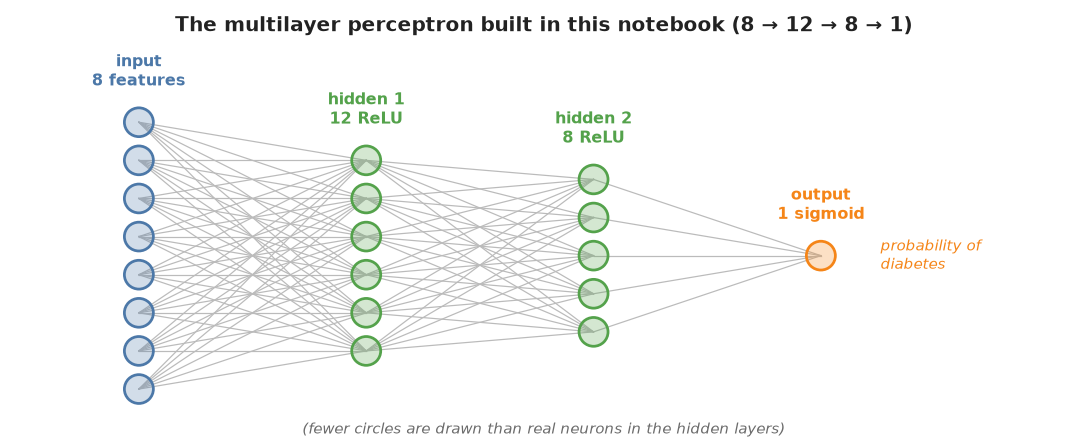

**Define the MLP**

In [4]:
from tensorflow import keras

model = keras.Sequential([
    keras.Input(shape=(8,)),
    keras.layers.Dense(12, activation="relu"),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid"),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12)             │           108 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 221 (884.00 B)

 Trainable params: 221 (884.00 B)

 Non-trainable params: 0 (0.00 B)

**Explanation:** Sequential stacks layers in order. Dense means fully connected. The two hidden layers use ReLU, and the output layer uses sigmoid to give a probability between 0 and 1. summary() lists each layer and its number of trainable weights.

**Compile and train the model**

In [5]:
import pandas as pd
from tensorflow import keras

keras.utils.set_random_seed(42)
dataset = pd.read_csv("diabetes.csv").values
X, y = dataset[:, 0:8].astype("float32"), dataset[:, 8].astype("float32")

model = keras.Sequential([
    keras.Input(shape=(8,)),
    keras.layers.Dense(12, activation="relu"),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid"),
])
model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])

history = model.fit(X, y, epochs=150, batch_size=10, validation_split=0.2, verbose=0)

print("Final training accuracy:  ", round(history.history["accuracy"][-1], 3))
print("Final validation accuracy:", round(history.history["val_accuracy"][-1], 3))

Final training accuracy:   0.769
Final validation accuracy: 0.714


**Explanation:** compile() chooses the loss (binary cross-entropy for a yes/no problem), the optimiser (Adam, an improved form of stochastic gradient descent) and the metric to report. fit() trains for 150 epochs in batches of 10 rows, holding back 20% of the rows to check performance on unseen data.

**Plot the learning curves**

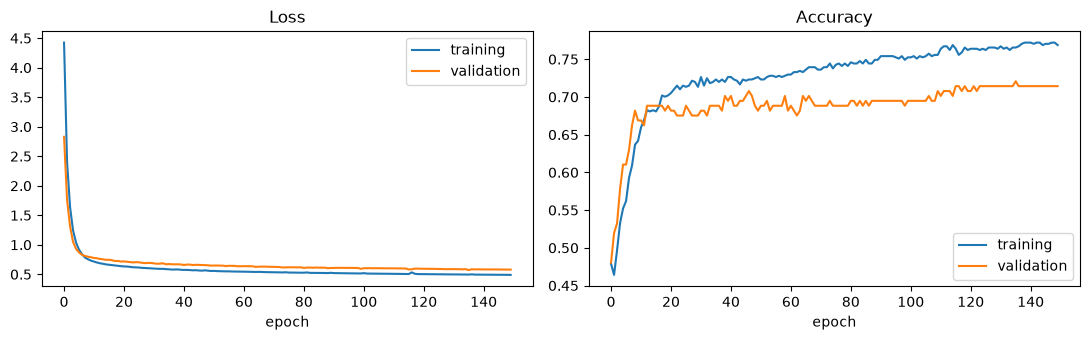

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras

keras.utils.set_random_seed(42)
dataset = pd.read_csv("diabetes.csv").values
X, y = dataset[:, 0:8].astype("float32"), dataset[:, 8].astype("float32")
model = keras.Sequential([keras.Input(shape=(8,)), keras.layers.Dense(12, activation="relu"),
                          keras.layers.Dense(8, activation="relu"), keras.layers.Dense(1, activation="sigmoid")])
model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])
history = model.fit(X, y, epochs=150, batch_size=10, validation_split=0.2, verbose=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(history.history["loss"], label="training")
axes[0].plot(history.history["val_loss"], label="validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(history.history["accuracy"], label="training")
axes[1].plot(history.history["val_accuracy"], label="validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout()
plt.show()

**Explanation:** The loss falls and the accuracy rises as training goes on. Comparing the training and validation curves shows whether the model is still improving on unseen data or starting to overfit.

**Scale the inputs and evaluate on a test set**

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow import keras

keras.utils.set_random_seed(42)
dataset = pd.read_csv("diabetes.csv").values
X, y = dataset[:, 0:8].astype("float32"), dataset[:, 8].astype("float32")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler().fit(X_train)
X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)

model = keras.Sequential([keras.Input(shape=(8,)), keras.layers.Dense(12, activation="relu"),
                          keras.layers.Dense(8, activation="relu"), keras.layers.Dense(1, activation="sigmoid")])
model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])
model.fit(X_train, y_train, epochs=150, batch_size=10, verbose=0)

loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {accuracy:.3f}")

Test accuracy: 0.695


**Explanation:** Neural networks train better when inputs are on similar scales, so StandardScaler gives every feature a mean of 0 and a standard deviation of 1. evaluate() measures accuracy on a test set the model never saw during training.

**Make predictions**

In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow import keras

keras.utils.set_random_seed(42)
dataset = pd.read_csv("diabetes.csv").values
X, y = dataset[:, 0:8].astype("float32"), dataset[:, 8].astype("float32")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler().fit(X_train)
X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)
model = keras.Sequential([keras.Input(shape=(8,)), keras.layers.Dense(12, activation="relu"),
                          keras.layers.Dense(8, activation="relu"), keras.layers.Dense(1, activation="sigmoid")])
model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])
model.fit(X_train, y_train, epochs=150, batch_size=10, verbose=0)

probabilities = model.predict(X_test[:5], verbose=0).ravel()
for p, actual in zip(probabilities, y_test[:5]):
    print(f"probability {p:.3f} -> predicted {int(p >= 0.5)} | actual {int(actual)}")

probability 0.710 -> predicted 1 | actual 0
probability 0.217 -> predicted 0 | actual 0
probability 0.289 -> predicted 0 | actual 0
probability 0.391 -> predicted 0 | actual 1
probability 0.001 -> predicted 0 | actual 0


**Explanation:** predict() returns a probability for each patient; rounding at 0.5 turns it into a class.

## Observation

- A neuron computes a weighted sum plus a bias and applies an activation function; an MLP stacks layers of these neurons.
- Hidden layers usually use ReLU, and a single sigmoid output gives a probability for a yes/no problem.
- The model is defined with Sequential and Dense layers, compiled with a loss, an optimiser and metrics, and trained with fit().
- Learning curves show the loss falling and the accuracy rising over the epochs.
- Scaling the inputs and testing on held-out data gives an honest measure of performance: about 70% accuracy on this data set, similar to the simpler models used on it earlier.

## Conclusion

The multilayer perceptron is the foundation of deep learning. Keras makes it possible to define, train and evaluate one in a few lines, while the same building blocks scale up to much larger networks.